# Model Robustness and Validation

## Credit Risk Analytics — Predicting Credit Card Default

This notebook evaluates whether the selected Random Forest behaves consistently across resampled training folds and descriptive customer subgroups. Cross-validation and out-of-fold predictions are kept separate from the final held-out test-set assessment.

## 1. Introduction and Objectives

Robust validation is important because one train/test split can overstate or understate performance. This notebook will: (1) reconstruct the established pipeline independently, (2) measure five-fold stratified performance stability, (3) examine precision-recall behaviour using out-of-fold predictions, (4) evaluate probability calibration, and (5) describe performance across age and gender subgroups. These analyses do not establish fairness, causation, or production readiness.

## 2. Independent Dataset and Environment Setup

The raw Excel dataset is loaded directly. Its first row contains the actual column names. Category standardization matches the established preprocessing methodology.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
current_directory = Path.cwd()
project_root = current_directory.parent if current_directory.name.lower() == "notebooks" else current_directory
data_path = project_root / "data" / "default of credit card clients.xls"
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {data_path}")

In [13]:
df_raw = pd.read_excel(data_path)
df = df_raw.copy()
df.columns = df.iloc[0].astype(str).str.strip()
df = df.iloc[1:].reset_index(drop=True).apply(pd.to_numeric)
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
target_column = "default payment next month"
print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Target distribution (%):")
print(df[target_column].value_counts(normalize=True).sort_index().mul(100).round(2))

Dataset shape: (30000, 25)
Missing values: 0
Target distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


## 3. Model Reconstruction

The preprocessing and Random Forest configuration below reproduce Notebook 04. Every transformation is inside the sklearn pipeline so that each cross-validation fold fits preprocessing only on its training portion.

In [14]:
nominal_features = ["SEX", "EDUCATION", "MARRIAGE"]
repayment_features = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
billing_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]
amount_columns = billing_columns + payment_columns
demographic_features = ["AGE"]
financial_features = ["LIMIT_BAL"]
categorical_features = nominal_features + repayment_features
feature_columns = nominal_features + repayment_features + financial_features + amount_columns + demographic_features
X = df[feature_columns].copy()
y = df[target_column].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

categorical_pipeline = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore"))])
standard_numeric_pipeline = Pipeline(steps=[("scaler", StandardScaler())])
amount_pipeline = Pipeline(steps=[("power_transform", PowerTransformer(method="yeo-johnson", standardize=False)), ("scaler", StandardScaler())])
preprocessor = ColumnTransformer(transformers=[("categorical", categorical_pipeline, categorical_features), ("standard_numeric", standard_numeric_pipeline, demographic_features + financial_features), ("amounts", amount_pipeline, amount_columns)], remainder="drop")

def make_model():
    return Pipeline(steps=[("preprocessor", preprocessor), ("classifier", RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1))])

model = make_model()
print("Predictors:", len(feature_columns))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Predictors: 23
Training shape: (24000, 23)
Testing shape: (6000, 23)


## 4. Stratified Cross-Validation

Five shuffled stratified folds are used with a fixed seed. The pipeline is cloned and fitted independently within each fold. These results estimate performance variability on the training dataset and are not the final held-out test result.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_results = cross_validate(make_model(), X_train, y_train, cv=cv, scoring=scoring, return_train_score=False, n_jobs=1)
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fold_scores = pd.DataFrame({metric: cv_results[f"test_{metric}"] for metric in metric_names})
fold_scores.index = np.arange(1, len(fold_scores) + 1)
fold_scores.index.name = "Fold"
print("Fold-level validation scores:")
display(fold_scores.round(4))

stability_summary = pd.DataFrame({
    "Mean": fold_scores.mean(),
    "Std": fold_scores.std(ddof=1),
    "Minimum": fold_scores.min(),
    "Maximum": fold_scores.max(),
})
print("Cross-validation stability summary:")
display(stability_summary.round(4))

Fold-level validation scores:


,accuracy,precision,recall,f1,roc_auc
Fold,,,,,
1,0.7875,0.5169,0.5919,0.5518,0.7868
2,0.7817,0.5056,0.5904,0.5447,0.7814
3,0.7794,0.5012,0.5791,0.5374,0.7726
4,0.7850,0.5126,0.5744,0.5417,0.7897
5,0.7854,0.5135,0.5734,0.5418,0.7820


Cross-validation stability summary:


,Mean,Std,Minimum,Maximum
accuracy,0.7838,0.0032,0.7794,0.7875
precision,0.5100,0.0064,0.5012,0.5169
recall,0.5818,0.0088,0.5734,0.5919
f1,0.5435,0.0054,0.5374,0.5518
roc_auc,0.7825,0.0065,0.7726,0.7897


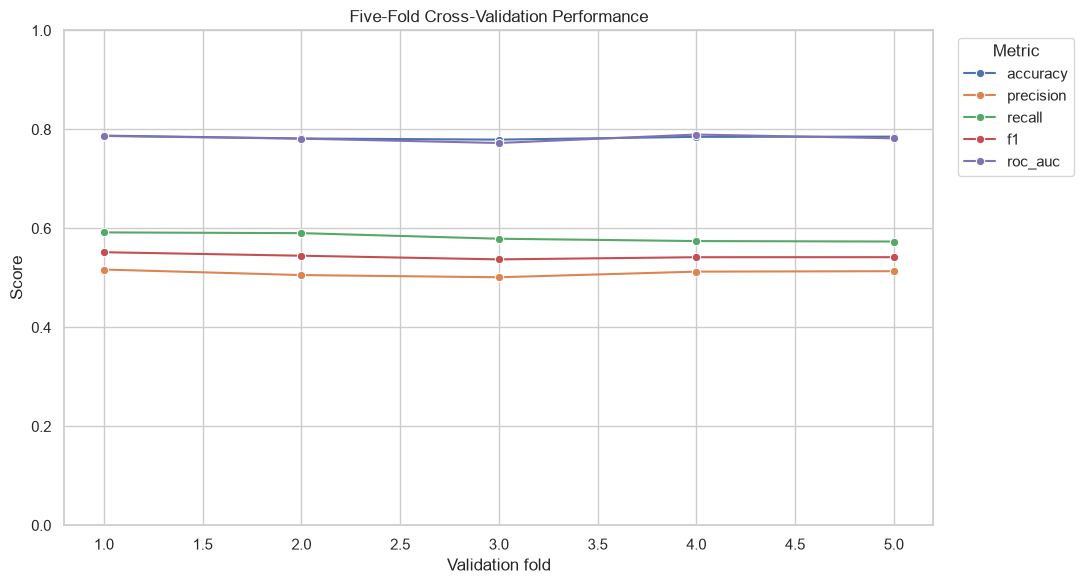

The fold ranges above describe stability; they do not prove future or production performance.


In [16]:
plot_scores = fold_scores.reset_index().melt(id_vars="Fold", var_name="Metric", value_name="Score")
plt.figure(figsize=(11, 6))
sns.lineplot(data=plot_scores, x="Fold", y="Score", hue="Metric", marker="o")
plt.title("Five-Fold Cross-Validation Performance")
plt.xlabel("Validation fold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print("The fold ranges above describe stability; they do not prove future or production performance.")

## 5. Precision-Recall Analysis

Precision-recall analysis is useful for an imbalanced default target because it focuses on the positive class and makes the trade-off between identifying defaults and limiting false alarms visible. The curve below uses out-of-fold training predictions: every probability is generated for a row by a model that did not train on that row. No final threshold is tuned on the test set.

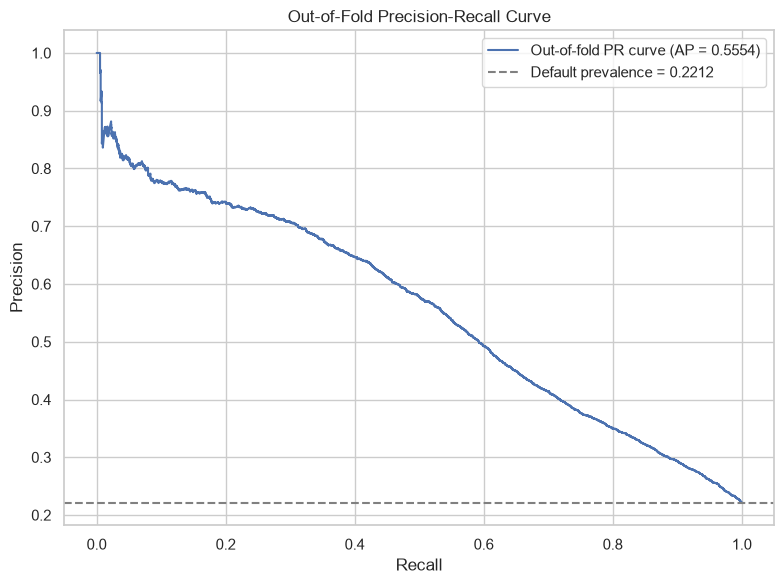

Average precision from out-of-fold predictions: 0.5554


In [17]:
oof_probability = cross_val_predict(make_model(), X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_train, oof_probability)
average_precision = average_precision_score(y_train, oof_probability)
plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, label=f"Out-of-fold PR curve (AP = {average_precision:.4f})")
plt.axhline(y_train.mean(), color="gray", linestyle="--", label=f"Default prevalence = {y_train.mean():.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-Fold Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()
print("Average precision from out-of-fold predictions:", round(average_precision, 4))

## 6. Probability Calibration

A calibrated probability should correspond approximately to the observed event frequency among cases receiving that score. Calibration is evaluated here with out-of-fold probabilities, a calibration curve, and the Brier score. Lower Brier scores are better, but the score alone does not establish that probabilities are suitable for operational decision-making.

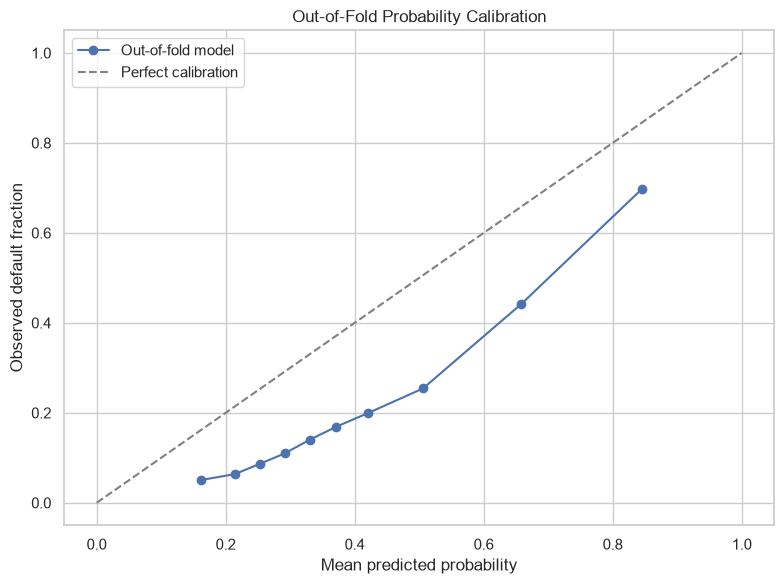

Out-of-fold Brier score: 0.1697
Calibration interpretation must consider the plotted deviations from the diagonal and should be confirmed on representative future data.


In [18]:
fraction_of_positives, mean_predicted_value = calibration_curve(y_train, oof_probability, n_bins=10, strategy="quantile")
brier_score = brier_score_loss(y_train, oof_probability)
plt.figure(figsize=(8, 6))
plt.plot(mean_predicted_value, fraction_of_positives, marker="o", label="Out-of-fold model")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default fraction")
plt.title("Out-of-Fold Probability Calibration")
plt.legend()
plt.tight_layout()
plt.show()
print("Out-of-fold Brier score:", round(brier_score, 4))
print("Calibration interpretation must consider the plotted deviations from the diagonal and should be confirmed on representative future data.")

## 7. Subgroup Performance Analysis

The final pipeline is fitted on the training split and evaluated once on the held-out test set. This descriptive analysis reports sample sizes and classification metrics for gender and age groups. It is not a fairness certification: subgroup selection, sample size, uncertainty intervals, calibration, intersectional groups, and protected-attribute governance require deeper analysis.

In [19]:
final_model = make_model()
final_model.fit(X_train, y_train)
test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.55).astype(int)
subgroup_test = X_test.copy()
subgroup_test["Actual"] = y_test.to_numpy()
subgroup_test["Predicted"] = test_prediction
subgroup_test["Gender group"] = subgroup_test["SEX"].map({1: "Male (code 1)", 2: "Female (code 2)"}).fillna("Other/unknown code")
subgroup_test["Age group"] = pd.cut(subgroup_test["AGE"], bins=[0, 25, 35, 45, 55, np.inf], labels=["<=25", "26-35", "36-45", "46-55", "56+"] , right=True)

def subgroup_metrics(data, group_column):
    rows = []
    for group_name, group in data.groupby(group_column, observed=False, dropna=False):
        actual = group["Actual"]
        predicted = group["Predicted"]
        rows.append({"Group": str(group_name), "Customers": len(group), "Default rate (%)": actual.mean() * 100, "Accuracy": accuracy_score(actual, predicted), "Precision": precision_score(actual, predicted, zero_division=0), "Recall": recall_score(actual, predicted, zero_division=0), "F1-score": f1_score(actual, predicted, zero_division=0)})
    return pd.DataFrame(rows)

gender_results = subgroup_metrics(subgroup_test, "Gender group")
age_results = subgroup_metrics(subgroup_test, "Age group")
print("Gender subgroup performance:")
display(gender_results.round(4))
print("Age subgroup performance:")
display(age_results.round(4))

Gender subgroup performance:


,Group,Customers,Default rate (%),Accuracy,Precision,Recall,F1-score
0,Female (code 2),3598,21.2896,0.8118,0.5614,0.5313,0.5459
1,Male (code 1),2402,23.3555,0.7860,0.5425,0.5348,0.5386


Age subgroup performance:


,Group,Customers,Default rate (%),Accuracy,Precision,Recall,F1-score
0,<=25,767,25.5541,0.7640,0.5346,0.5918,0.5617
1,26-35,2492,19.6629,0.8186,0.5408,0.5143,0.5272
2,36-45,1775,22.3662,0.8090,0.5792,0.5340,0.5557
3,46-55,788,25.1269,0.7754,0.5561,0.5253,0.5403
4,56+,178,25.8427,0.7640,0.5476,0.5000,0.5227


## 8. Fairness Considerations

Differences between subgroup metrics can reflect sampling variation, feature distribution differences, measurement choices, or model behaviour. They do not by themselves prove discrimination or fairness. A broader assessment would require predefined fairness objectives, confidence intervals, intersectional analysis, calibration by group, error-cost analysis, legal and domain review, and careful consideration of whether demographic features should be used. Historical data can encode structural inequities, so model governance and human oversight remain necessary.

## 9. Final Robustness Assessment

Cross-validation stability, the out-of-fold precision-recall curve, calibration evidence, and subgroup tables should be read together. A stable mean across folds would support repeatability on similar sampled data, but would not establish temporal or geographic generalization. Precision-recall results show the cost of trading recall for precision. The calibration curve and Brier score provide evidence about probability quality, without justifying an unsupported calibration claim. Subgroup metrics are descriptive and require uncertainty-aware fairness analysis before operational use.

In [20]:
reference_test_metrics = pd.Series({"Accuracy": 0.8015, "Precision": 0.5532, "Recall": 0.5328, "F1-score": 0.5428, "ROC-AUC": 0.7762})
test_metrics = pd.Series({"Accuracy": accuracy_score(y_test, test_prediction), "Precision": precision_score(y_test, test_prediction, zero_division=0), "Recall": recall_score(y_test, test_prediction, zero_division=0), "F1-score": f1_score(y_test, test_prediction, zero_division=0), "ROC-AUC": roc_auc_score(y_test, test_probability)})
print("Held-out test metrics at threshold 0.55 (not used for tuning):")
display(pd.DataFrame({"Recalculated": test_metrics, "Notebook 04 reference": reference_test_metrics}).round(4))
print("Robustness summary:")
print("- Cross-validation mean scores:")
print(stability_summary["Mean"].round(4).to_string())
print("- Cross-validation standard deviations:")
print(stability_summary["Std"].round(4).to_string())
print("- Out-of-fold average precision:", round(average_precision, 4))
print("- Out-of-fold Brier score:", round(brier_score, 4))
print("- Subgroup results are descriptive and do not certify fairness.")

Held-out test metrics at threshold 0.55 (not used for tuning):


,Recalculated,Notebook 04 reference
Accuracy,0.8015,0.8015
Precision,0.5532,0.5532
Recall,0.5328,0.5328
F1-score,0.5428,0.5428
ROC-AUC,0.7762,0.7762


Robustness summary:
- Cross-validation mean scores:
accuracy     0.7838
precision    0.5100
recall       0.5818
f1           0.5435
roc_auc      0.7825
- Cross-validation standard deviations:
accuracy     0.0032
precision    0.0064
recall       0.0088
f1           0.0054
roc_auc      0.0065
- Out-of-fold average precision: 0.5554
- Out-of-fold Brier score: 0.1697
- Subgroup results are descriptive and do not certify fairness.


## 10. Conclusion

This validation review tests the selected model beyond one reported split while preserving the original preprocessing and model definition. The results provide evidence about sampled performance variability, positive-class trade-offs, probability quality, and subgroup differences. Before production use, the project would still require temporal and external validation, probability calibration, uncertainty analysis, fairness assessment, drift monitoring, documented error costs, and human governance.